# 경기 특성별 신규 판매량 회귀분석

**질문: 어떤 경기가 신규 판매를 얼마나 더 끌어오는가?**

실무에서는 리그·빅매치 여부 같은 도메인 변수로 경기 중요도 기준을 직접 세우고, 그 기준에 따라 CRM 발송 채널과 규모를 나눴습니다.
이 노트북은 같은 질문을 **회귀분석**으로 다시 풀어봅니다.

- 각 변수가 판매에 주는 영향을 **배수**로 정량화
- 과거 데이터로 학습하고 이후 기간으로 **예측력을 검증**
- 예측값을 CRM 발송 등급으로 연결

> ※ `generate_ott_data_v3.py`로 생성한 **가상 데이터**를 사용합니다. 실제 서비스 데이터·지표와 무관합니다.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from matplotlib import font_manager

# 한글 폰트: Windows는 맑은 고딕, 없으면 설치된 다른 한글 폰트 사용
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if _f in _installed:
        plt.rcParams["font.family"] = _f
        break
plt.rcParams["axes.unicode_minus"] = False
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
pd.set_option("display.float_format", "{:.3f}".format)

## 1. 데이터 준비

경기 1건 = 1행. 종속변수는 **해당 경기에 귀속된 결제 수**(최초 + 복귀)입니다.
경기 귀속 기준은 기존 파이프라인과 같이 `purchases.trigger_match_id`(결제 후 첫 시청 경기)를 씁니다.

In [2]:
conn = sqlite3.connect("portfolio.db")
df = pd.read_sql("""
    SELECT m.match_id, m.match_date, m.category, m.is_big_match,
           COUNT(p.purchase_id) AS sales
    FROM matches m
    LEFT JOIN purchases p ON p.trigger_match_id = m.match_id
    GROUP BY m.match_id
""", conn)
conn.close()

df["match_date"] = pd.to_datetime(df["match_date"])
df["is_weekend"] = (df["match_date"].dt.dayofweek >= 5).astype(int)

CAT_KR = {"baseball": "야구", "soccer": "축구", "golf": "골프",
          "ufc": "UFC", "basketball": "농구", "volleyball": "배구"}
df["종목"] = df["category"].map(CAT_KR)
print(f"경기 {len(df):,}건 / 기간 {df.match_date.min():%Y-%m-%d} ~ {df.match_date.max():%Y-%m-%d}")
df.head()

경기 842건 / 기간 2025-01-06 ~ 2026-07-19


,match_id,match_date,category,is_big_match,sales,is_weekend,종목
0,1,2025-01-09,soccer,0,8,0,축구
1,2,2025-01-09,soccer,0,9,0,축구
2,3,2025-01-07,soccer,0,12,0,축구
3,4,2025-01-09,soccer,0,12,0,축구
4,5,2025-01-07,ufc,0,6,0,UFC


## 2. 탐색: 종목·빅매치별 평균 판매

In [3]:
eda = (df.groupby(["종목", "is_big_match"])["sales"]
         .agg(경기수="count", 평균판매="mean")
         .unstack("is_big_match"))
eda.columns = [f"{a}_{'빅매치' if b else '일반'}" for a, b in eda.columns]
eda.sort_values("평균판매_일반", ascending=False)

,경기수_일반,경기수_빅매치,평균판매_일반,평균판매_빅매치
종목,,,,
야구,245.000,37.000,9.457,27.946
축구,184.000,13.000,8.022,23.462
UFC,27.000,NaN,6.889,NaN
농구,150.000,19.000,4.567,14.053
골프,72.000,14.000,4.014,12.714
배구,73.000,8.000,2.945,9.250


단순 평균만 봐도 종목 차이와 빅매치 효과가 보입니다. 다만 평균 비교는 **변수끼리 섞인 효과를 분리하지 못합니다**
(예: 빅매치가 특정 종목에 몰려 있으면 빅매치 효과가 부풀려짐). 그래서 변수를 함께 넣은 회귀로 각 효과를 분리합니다.

## 3. 모델: 포아송 회귀

판매량은 0 이상의 **정수(건수)** 라서 일반 선형회귀보다 포아송 회귀가 맞습니다.
포아송 회귀는 계수를 `exp(계수)`로 바꾸면 **"다른 조건이 같을 때 판매가 몇 배가 되는가"** 로 바로 읽을 수 있습니다.

- 기준 종목: 골프
- 변수: 종목, 빅매치 여부, 주말 여부
- 검증을 위해 **2026-03-01 이전으로 학습**, 이후 기간은 테스트용으로 남겨둠

In [4]:
SPLIT = "2026-03-01"
train = df[df.match_date < SPLIT].copy()
test = df[df.match_date >= SPLIT].copy()
print(f"학습 {len(train)}건 / 테스트 {len(test)}건")

formula = 'sales ~ C(종목, Treatment("골프")) + is_big_match + is_weekend'
model = smf.glm(formula, data=train, family=sm.families.Poisson()).fit()

# 과산포 체크: 1에 가까우면 포아송 가정이 맞음 (크게 넘으면 음이항 회귀 고려)
print(f"과산포 지표(Pearson χ² / 자유도): {model.pearson_chi2 / model.df_resid:.2f}")

학습 636건 / 테스트 206건
과산포 지표(Pearson χ² / 자유도): 1.07


In [5]:
ci = model.conf_int()
res = pd.DataFrame({
    "배수 exp(β)": np.exp(model.params),
    "95% CI 하한": np.exp(ci[0]),
    "95% CI 상한": np.exp(ci[1]),
    "p-value": model.pvalues,
}).drop("Intercept")
res.index = (res.index.str.replace(r'C\(종목, Treatment\("골프"\)\)\[T\.(.+)\]', r"\1 (vs 골프)", regex=True)
                      .str.replace("is_big_match", "빅매치")
                      .str.replace("is_weekend", "주말 경기"))
res

,배수 exp(β),95% CI 하한,95% CI 상한,p-value
UFC (vs 골프),1.718,1.405,2.100,0.000
농구 (vs 골프),1.194,1.048,1.361,0.008
배구 (vs 골프),0.791,0.671,0.932,0.005
야구 (vs 골프),2.194,1.951,2.468,0.000
축구 (vs 골프),2.103,1.863,2.374,0.000
빅매치,3.005,2.809,3.215,0.000
주말 경기,1.035,0.973,1.101,0.271


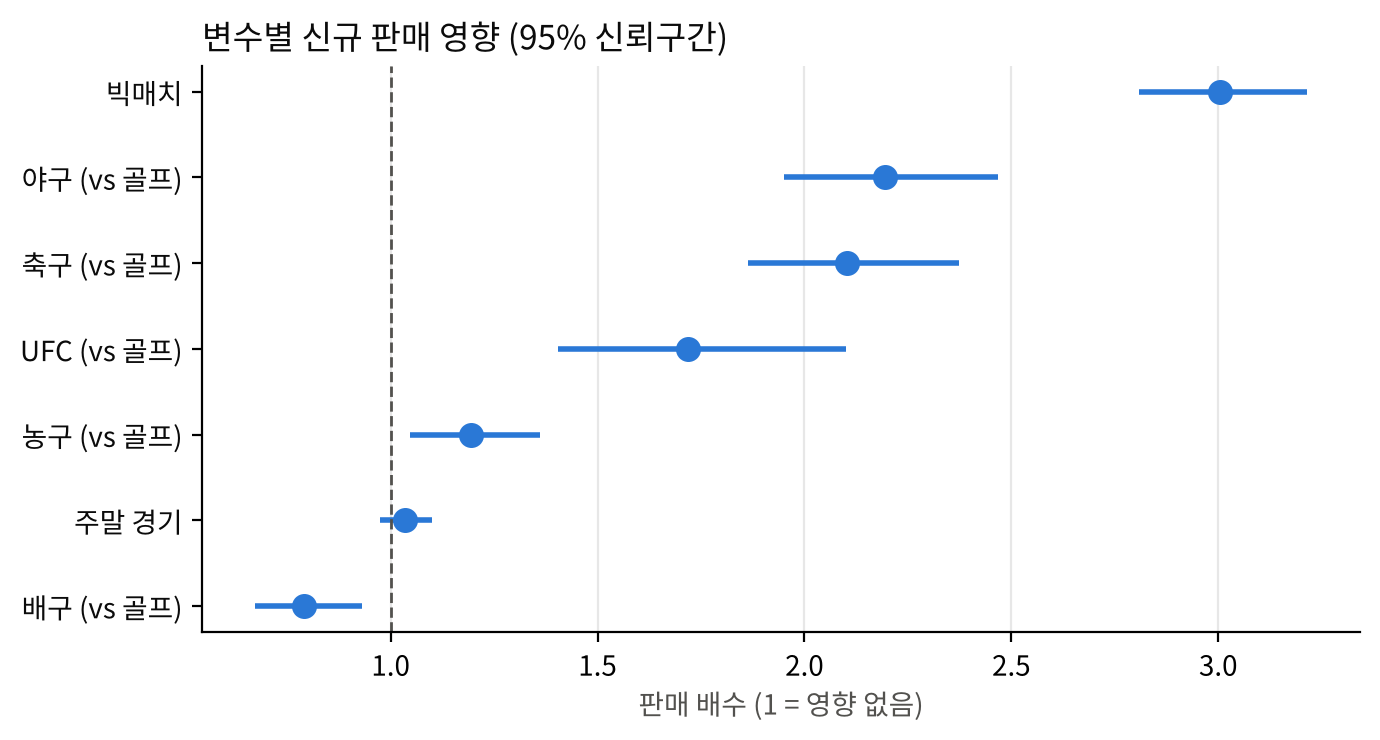

In [6]:
plot = res.sort_values("배수 exp(β)")
fig, ax = plt.subplots(figsize=(7, 3.8))
y = np.arange(len(plot))
ax.errorbar(plot["배수 exp(β)"], y,
            xerr=[plot["배수 exp(β)"] - plot["95% CI 하한"], plot["95% CI 상한"] - plot["배수 exp(β)"]],
            fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=0, markersize=8)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_yticks(y, plot.index, color=INK)
ax.set_xlabel("판매 배수 (1 = 영향 없음)", color=MUTED)
ax.set_title("변수별 신규 판매 영향 (95% 신뢰구간)", loc="left", color=INK)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**해석**
- **빅매치**는 다른 조건이 같을 때 판매가 약 3배입니다. 신뢰구간도 좁아 가장 확실한 변수입니다.
- **종목**: 골프 대비 야구·축구가 크게 높고, 배구는 낮습니다.
- **주말 경기**는 신뢰구간이 1을 포함해 **유의하지 않습니다.** 가상 데이터 생성 시 요일 효과를 넣지 않았기 때문에 나와야 할 결과가 나온 것으로, 모델이 없는 효과를 만들어내지 않는다는 확인이기도 합니다.

> 위 수치는 데이터 생성 시 넣은 설정값(빅매치 3배, 종목별 가중치)을 모델이 다시 찾아낸 것입니다. 이 노트북의 목적은 **방법론 검증**입니다.

## 4. 검증: 학습에 안 쓴 기간으로 예측

모델이 실제로 쓸모 있으려면 단순 규칙보다 잘 맞아야 합니다. 테스트 기간(2026-03-01 이후)에서 **평균 절대 오차(MAE)** 를 비교합니다.

- 베이스라인 1: 전체 평균으로 예측
- 베이스라인 2: 종목별 평균으로 예측 (종목만 보는 단순 규칙)

In [7]:
test["pred"] = model.predict(test)
base_all = train["sales"].mean()
base_cat = test["종목"].map(train.groupby("종목")["sales"].mean())

mae = pd.Series({
    "전체 평균": (test.sales - base_all).abs().mean(),
    "종목별 평균": (test.sales - base_cat).abs().mean(),
    "포아송 회귀": (test.sales - test.pred).abs().mean(),
}, name="MAE (건)")
mae.to_frame()

,MAE (건)
전체 평균,5.398
종목별 평균,4.281
포아송 회귀,3.177


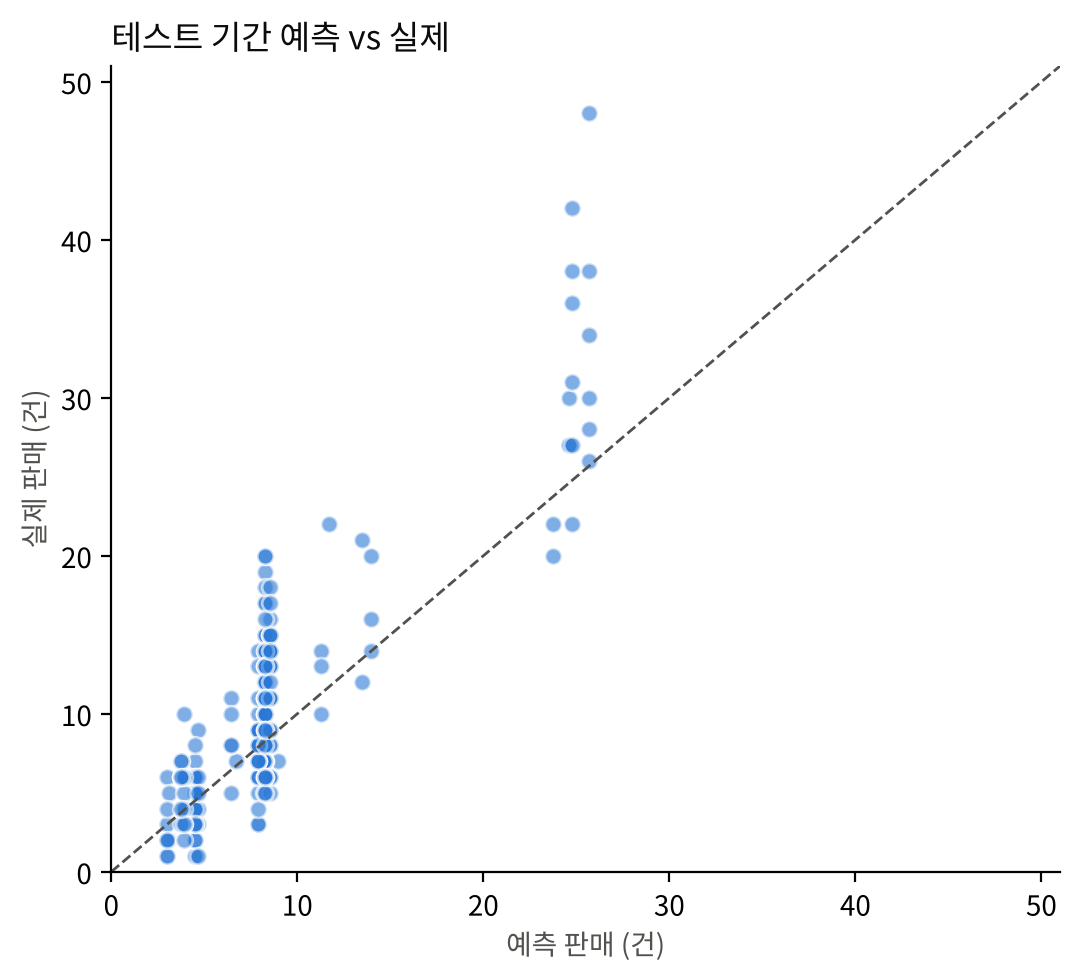

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
lim = max(test.sales.max(), test.pred.max()) + 3
ax.scatter(test.pred, test.sales, s=36, color=BLUE, alpha=0.6, edgecolors="white", linewidths=1)
ax.plot([0, lim], [0, lim], color=MUTED, lw=1, ls="--")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("예측 판매 (건)", color=MUTED)
ax.set_ylabel("실제 판매 (건)", color=MUTED)
ax.set_title("테스트 기간 예측 vs 실제", loc="left", color=INK)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

회귀 모델이 두 베이스라인보다 오차가 작습니다. 다만 점들이 대각선 **위쪽**에 더 많이 몰려 있습니다. 실제가 예측보다 높은 쪽으로 치우쳐 있다는 뜻이라, 편향을 따로 확인합니다.

In [9]:
bias = pd.DataFrame({
    "평균 예측": [train.assign(p=model.predict(train))["p"].mean(), test["pred"].mean()],
    "평균 실제": [train["sales"].mean(), test["sales"].mean()],
}, index=["학습 기간", "테스트 기간"])
bias["실제 - 예측"] = bias["평균 실제"] - bias["평균 예측"]
bias

,평균 예측,평균 실제,실제 - 예측
학습 기간,7.574,7.574,0.000
테스트 기간,8.638,10.723,2.086


학습 기간에는 평균이 맞지만, 테스트 기간에는 **실제가 예측보다 체계적으로 높습니다.**
원인을 확인하기 위해 경기 귀속 판매를 최초/복귀로 나눠 기간별로 봅니다.

In [10]:
conn = sqlite3.connect("portfolio.db")
trend = pd.read_sql("""
    SELECT substr(m.match_date, 1, 7) AS 월, p.purchase_type AS 구분, COUNT(*) AS 판매
    FROM purchases p JOIN matches m ON p.trigger_match_id = m.match_id
    GROUP BY 1, 2
""", conn)
n_match = pd.read_sql("SELECT substr(match_date, 1, 7) AS 월, COUNT(*) AS 경기수 FROM matches GROUP BY 1", conn)
conn.close()
trend = trend.pivot(index="월", columns="구분", values="판매").fillna(0).join(n_match.set_index("월"))
trend["경기당 최초"] = trend["최초"] / trend["경기수"]
trend["경기당 복귀"] = trend["복귀"] / trend["경기수"]
trend[["경기수", "경기당 최초", "경기당 복귀"]]

,경기수,경기당 최초,경기당 복귀
월,,,
2025-01,36,6.278,0.000
2025-02,39,5.590,0.000
2025-03,65,6.323,0.000
2025-04,48,7.292,0.000
2025-05,46,8.283,0.022
2025-06,24,7.083,0.167
2025-07,36,11.833,0.167
2025-08,41,10.366,0.195
2025-09,60,8.400,0.200


**경기당 최초 결제는 월마다 오르내릴 뿐 뚜렷한 추세가 없는데, 경기당 복귀 결제는 2025년 초 0건에서 2026년 7월 5건대까지 꾸준히 늘어납니다.**
해지자가 누적될수록 돌아올 수 있는 사람도 많아지기 때문입니다. 모델에는 이 시간 추세 변수가 없어서 후반 기간을 낮게 예측했습니다.

→ 개선 방향: 최초/복귀를 **따로 모델링**하거나, 복귀 모델에 "그 시점 누적 해지자 수" 같은 변수를 추가합니다.

## 5. 실무 적용: 예측값 → CRM 발송 등급

예측 판매를 기준으로 경기를 3등급으로 나누면, 발송 채널과 규모를 정하는 기준으로 쓸 수 있습니다.
(등급 경계와 채널 매핑은 예시입니다.)

In [11]:
q_hi, q_mid = train.assign(pred=model.predict(train))["pred"].quantile([0.85, 0.5])

def grade(p):
    if p >= q_hi:
        return "A (LMS + 뉴스레터)"
    if p >= q_mid:
        return "B (뉴스레터)"
    return "C (발송 없음)"

test["등급"] = test["pred"].apply(grade)
summary = (test.groupby("등급")
               .agg(경기수=("match_id", "count"), 평균예측=("pred", "mean"), 평균실제=("sales", "mean"),
                    판매합계=("sales", "sum")))
summary["판매 비중"] = summary["판매합계"] / summary["판매합계"].sum()
summary

,경기수,평균예측,평균실제,판매합계,판매 비중
등급,,,,,
A (LMS + 뉴스레터),53,14.517,18.679,990,0.448
B (뉴스레터),91,8.154,10.165,925,0.419
C (발송 없음),62,4.321,4.742,294,0.133


## 6. 한계와 다음 단계

- **가상 데이터**: 효과를 직접 설정한 데이터라 모델이 잘 맞는 것은 당연합니다. 실제 데이터에서는 노이즈가 훨씬 큽니다.
- **변수 부족**: 실제로는 중계 시간대, 상대팀, 해외 리그의 한국 선수 출전 여부, 시즌 단계(개막·결승) 같은 변수가 필요합니다.
- **귀속 기준**: "결제 후 첫 시청 경기" 귀속은 하나의 가정입니다. 경기 직전 결제를 귀속하는 등 다른 기준과 비교해 볼 수 있습니다.
- **시간 추세 미반영**: 4장에서 확인한 것처럼 복귀 결제 증가 추세를 반영하지 못해 후반 기간을 과소 예측합니다.
- **다음 단계**: 최초/복귀 분리 모델링. 과산포가 큰 실제 데이터라면 음이항 회귀로 바꾸고, 시계열 교차검증으로 기간별 안정성을 확인합니다.